# Product Analytics Platform — аналитический разбор для стейкхолдеров

Ноутбук отвечает на вопросы, которые обычно задаёт менеджмент SaaS-продукта:
**как растёт аудитория, насколько хорошо мы удерживаем пользователей, как
работает воронка активации и откуда берётся выручка.**

Все данные — синтетические (генератор `src/generator`), прогнаны через ELT в
DuckDB (`src/pipeline`) и агрегированы слоем метрик (`src/metrics`). Ноутбук
читает готовые витрины и `metric_*` таблицы из `data/warehouse.duckdb`.

> Перед запуском ноутбука соберите данные: `make pipeline`.


In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
PAL = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2"]

con = duckdb.connect("../data/warehouse.duckdb", read_only=True)
ANALYSIS_END = "2025-08-31"
print("Таблиц в warehouse:", len(con.execute("SHOW TABLES").fetchall()))


Таблиц в warehouse: 16


## 1. Headline-показатели

Единый свод ключевых KPI на конец окна анализа.

In [2]:
s = con.execute("SELECT * FROM metric_summary").df().iloc[0]
summary = pd.DataFrame({
    "Метрика": ["Всего пользователей", "Платящих сейчас", "Free → Paid",
                "Отток платящих", "North Star (WAU)", "Текущий MRR", "Выручка всего"],
    "Значение": [f"{int(s.total_users):,}", f"{int(s.paying_users):,}",
                 f"{s.free_to_paid_rate:.1%}", f"{s.paid_churn_rate:.1%}",
                 f"{int(s.north_star_wau):,}", f"${s.current_mrr:,.0f}",
                 f"${s.total_revenue:,.0f}"],
})
summary


,Метрика,Значение
0,Всего пользователей,"9,306"
1,Платящих сейчас,704
2,Free → Paid,10.4%
3,Отток платящих,27.2%
4,North Star (WAU),"1,816"
5,Текущий MRR,"$34,876"
6,Выручка всего,"$240,046"


## 2. Рост аудитории: DAU / WAU / MAU

Аудитория устойчиво растёт весь год. В DAU хорошо видна недельная сезонность
(будни выше выходных), а всплески привлечения совпадают с маркетинговыми
кампаниями (например, Black Friday).

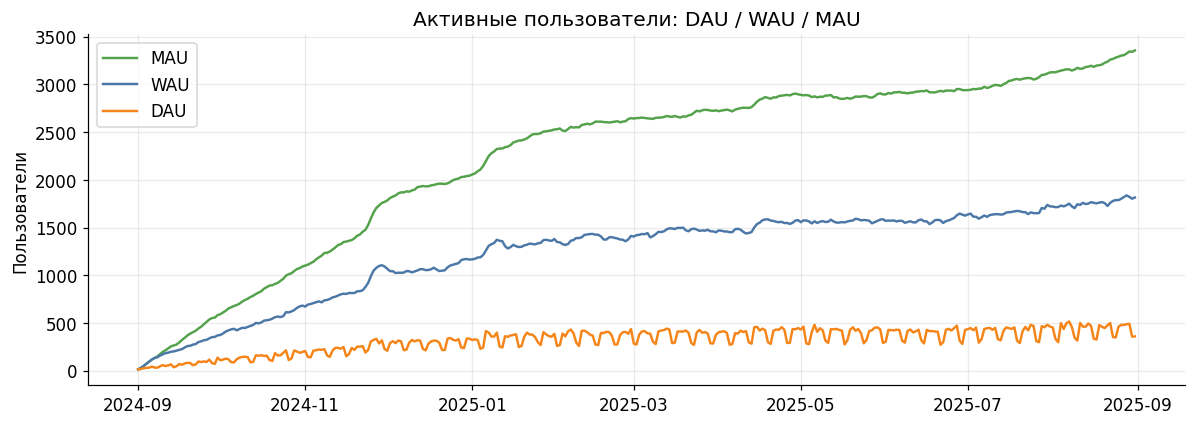

WAU за год вырос с 134 до 1816


In [3]:
au = con.execute(f'''
    SELECT activity_date, dau, wau, mau
    FROM metric_active_users WHERE activity_date <= DATE '{ANALYSIS_END}' ORDER BY 1''').df()
fig, ax = plt.subplots(figsize=(11, 4))
for col, c in zip(["mau", "wau", "dau"], [PAL[2], PAL[0], PAL[1]]):
    ax.plot(au.activity_date, au[col], label=col.upper(), color=c, lw=1.6)
ax.set_title("Активные пользователи: DAU / WAU / MAU")
ax.legend(loc="upper left"); ax.set_ylabel("Пользователи")
plt.tight_layout(); plt.show()
print("WAU за год вырос с", int(au.wau.iloc[6]), "до", int(au.wau.iloc[-1]))


## 3. Удержание по когортам

Классический паттерн: резкое падение после первой недели и стабилизация «плато»
у лояльного ядра. Ниже — day-N retention по всей базе.

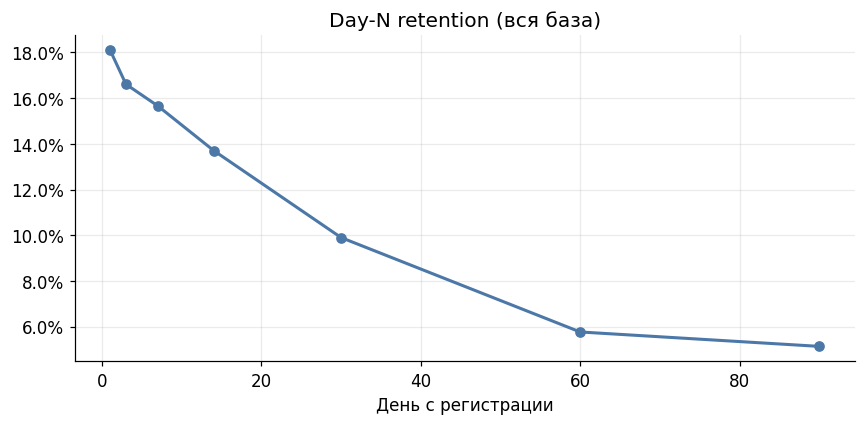

,day_number,retention
0,1,18.1%
1,3,16.6%
2,7,15.7%
3,14,13.7%
4,30,9.9%
5,60,5.8%
6,90,5.1%


In [4]:
r = con.execute("SELECT day_number, retention_rate FROM metric_retention_dayn ORDER BY 1").df()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r.day_number, r.retention_rate, "o-", color=PAL[0], lw=2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Day-N retention (вся база)"); ax.set_xlabel("День с регистрации")
plt.tight_layout(); plt.show()
r.assign(retention=r.retention_rate.map("{:.1%}".format))[["day_number", "retention"]]


## 4. Воронка активации

Строго вложенная воронка `signup → login → create_project → run_report → purchase`.
Главный «обрыв» — переход к оплате: до продукта доходят почти все, но платит
лишь малая доля. Это ключевая точка роста монетизации.

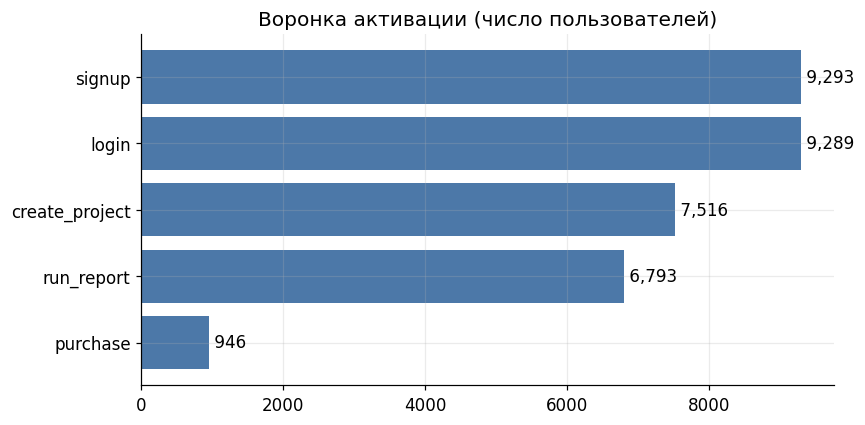

,step,users,conv_from_prev
0,signup,9293,100.0%
1,login,9289,100.0%
2,create_project,7516,80.9%
3,run_report,6793,90.4%
4,purchase,946,13.9%


In [5]:
f = con.execute("SELECT step, users, conv_from_prev FROM metric_activation_funnel ORDER BY step_order").df()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(f.step[::-1], f.users[::-1], color=PAL[0])
for i, (u, s) in enumerate(zip(f.users[::-1], f.step[::-1])):
    ax.text(u, i, f" {u:,}", va="center")
ax.set_title("Воронка активации (число пользователей)")
plt.tight_layout(); plt.show()
f.assign(conv_from_prev=f.conv_from_prev.map("{:.1%}".format))


## 5. Выручка и сегменты

MRR стабильно растёт за счёт притока платящих. Разбивка по планам показывает
вклад `pro` и `enterprise`; разбивка по каналам — какие источники приносят
деньги, а не только регистрации.

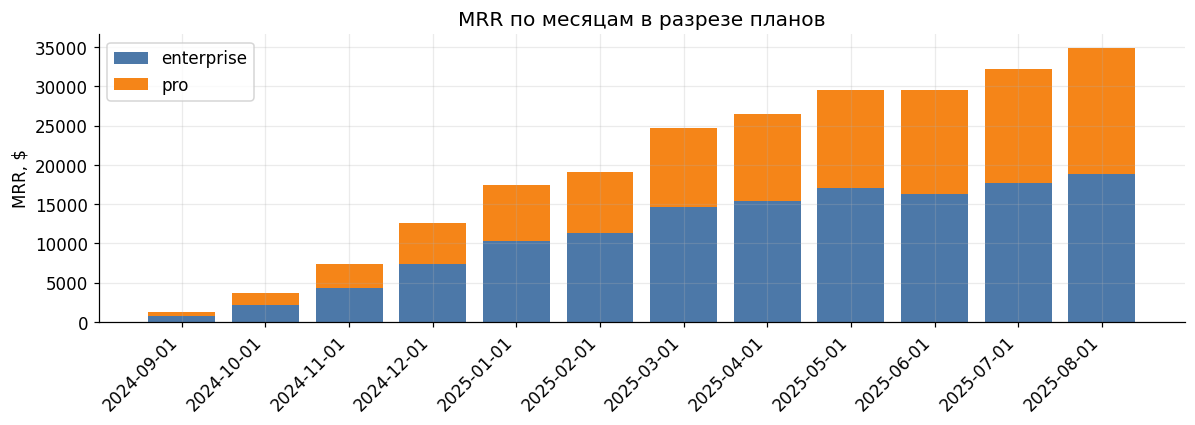

In [6]:
mrr = con.execute(f'''
    SELECT event_month, plan, mrr FROM metric_mrr
    WHERE event_month <= date_trunc('month', DATE '{ANALYSIS_END}') ORDER BY 1''').df()
piv = mrr.pivot(index="event_month", columns="plan", values="mrr").fillna(0)
fig, ax = plt.subplots(figsize=(11, 4))
bottom = None
for i, plan in enumerate(piv.columns):
    ax.bar(piv.index.astype(str), piv[plan], bottom=bottom, label=plan, color=PAL[i % len(PAL)], width=.8)
    bottom = piv[plan] if bottom is None else bottom + piv[plan]
ax.set_title("MRR по месяцам в разрезе планов"); ax.legend()
plt.xticks(rotation=45, ha="right"); ax.set_ylabel("MRR, $")
plt.tight_layout(); plt.show()


In [7]:
seg = con.execute('''
    SELECT segment_value AS channel, users, paying_users, conversion_rate, revenue
    FROM metric_segments WHERE segment_type='channel' ORDER BY revenue DESC''').df()
seg.assign(conversion_rate=seg.conversion_rate.map("{:.1%}".format),
           revenue=seg.revenue.map("${:,.0f}".format))


,channel,users,paying_users,conversion_rate,revenue
0,organic,4143,311.0,10.4%,"$103,591"
1,paid,3265,260.0,10.2%,"$79,368"
2,referral,1898,133.0,10.6%,"$57,087"


## 6. Выводы для стейкхолдеров

1. **Рост здоровый.** WAU и MAU растут весь год, недельная сезонность и отклик
   на маркетинговые кампании подтверждают, что каналы привлечения работают.
2. **Удержание — точка роста.** Основная просадка приходится на первую неделю.
   Инвестиции в онбординг и активацию первого дня напрямую поднимут retention.
3. **Монетизация упирается в оплату.** Продуктовые шаги воронки проходят почти
   все, но конверсия в оплату низкая — приоритет для экспериментов с
   ценообразованием и триггерами апгрейда.
4. **Сегменты различаются.** Power-пользователи держатся кратно лучше и платят
   чаще — их стоит растить как источник и LTV, и рефералов.
5. **Отток платящих под контролем**, но требует мониторинга: рост MRR не должен
   маскировать возможное ускорение churn в отдельных когортах.

*Дальше:* добавить прогноз MRR, LTV/CAC по каналам и A/B-тесты онбординга.
